In [1]:
import sys

print("Python version:", sys.version)

!nvidia-smi


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Sun Oct 18 08:56:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |     

In [2]:
from google.colab import files

uploaded = files.upload()


Saving Construction Site Safety.v1i.yolov8.zip to Construction Site Safety.v1i.yolov8.zip


In [5]:
import zipfile
import os

zip_path = "/content/Construction Site Safety.v1i.yolov8.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete.")
print("Top-level contents:", os.listdir(extract_path))


Extraction complete.
Top-level contents: ['train', 'valid', 'README.roboflow.txt', 'test', 'data.yaml', 'README.dataset.txt']


In [7]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 71.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.5 MB/s eta 0:00:00


Training artifacts:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
results.png

Saved validation prediction images:
val_batch0_pred.jpg
val_batch1_pred.jpg
val_batch2_pred.jpg

results.png


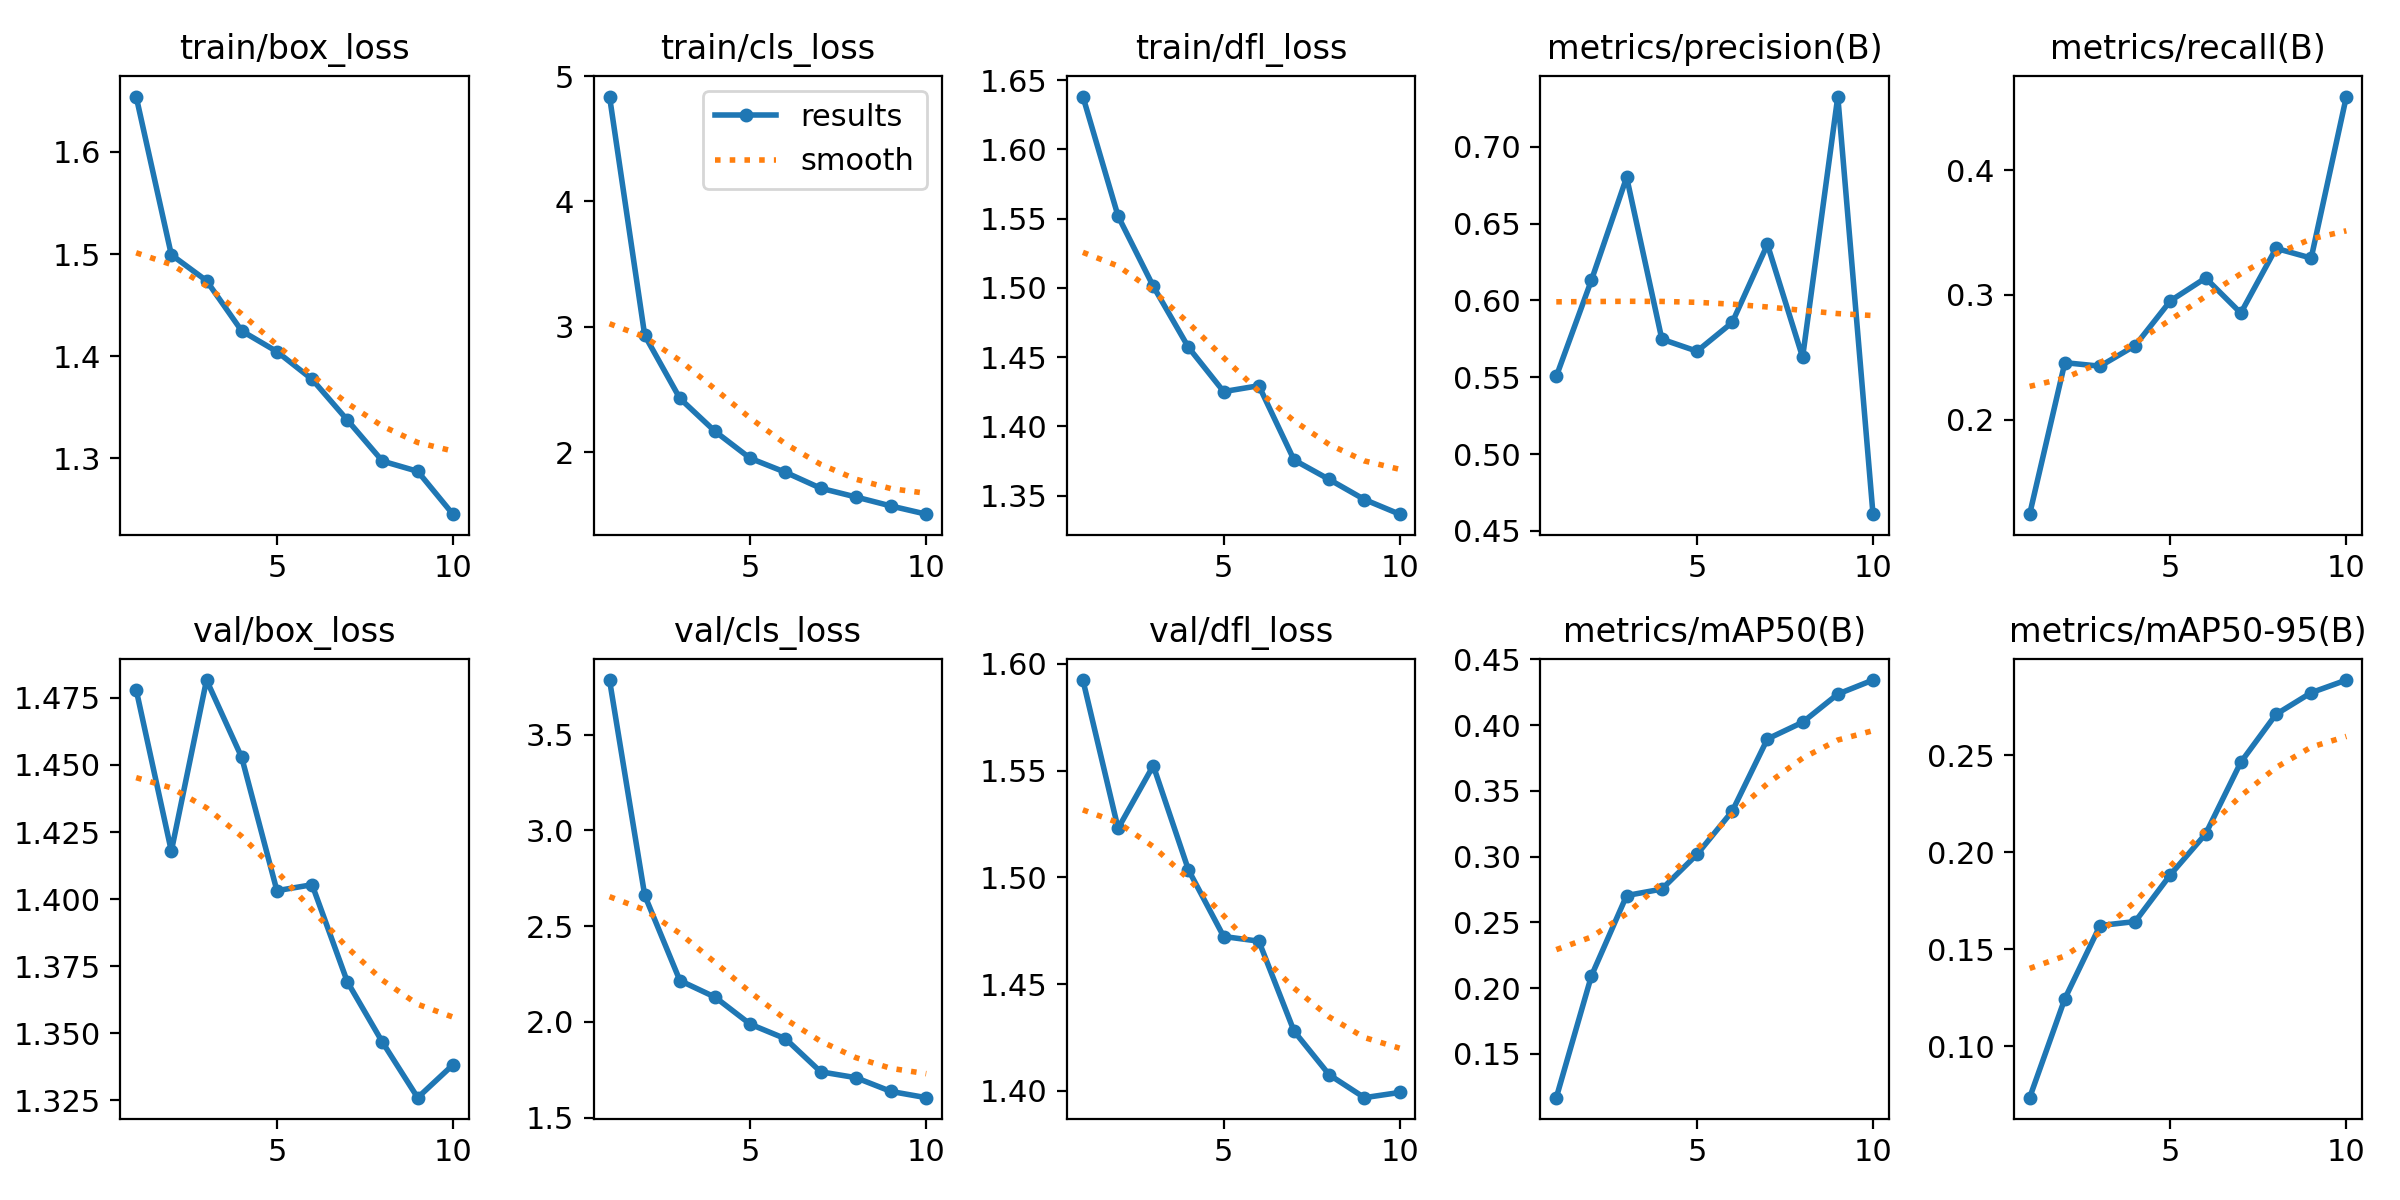


confusion_matrix.png


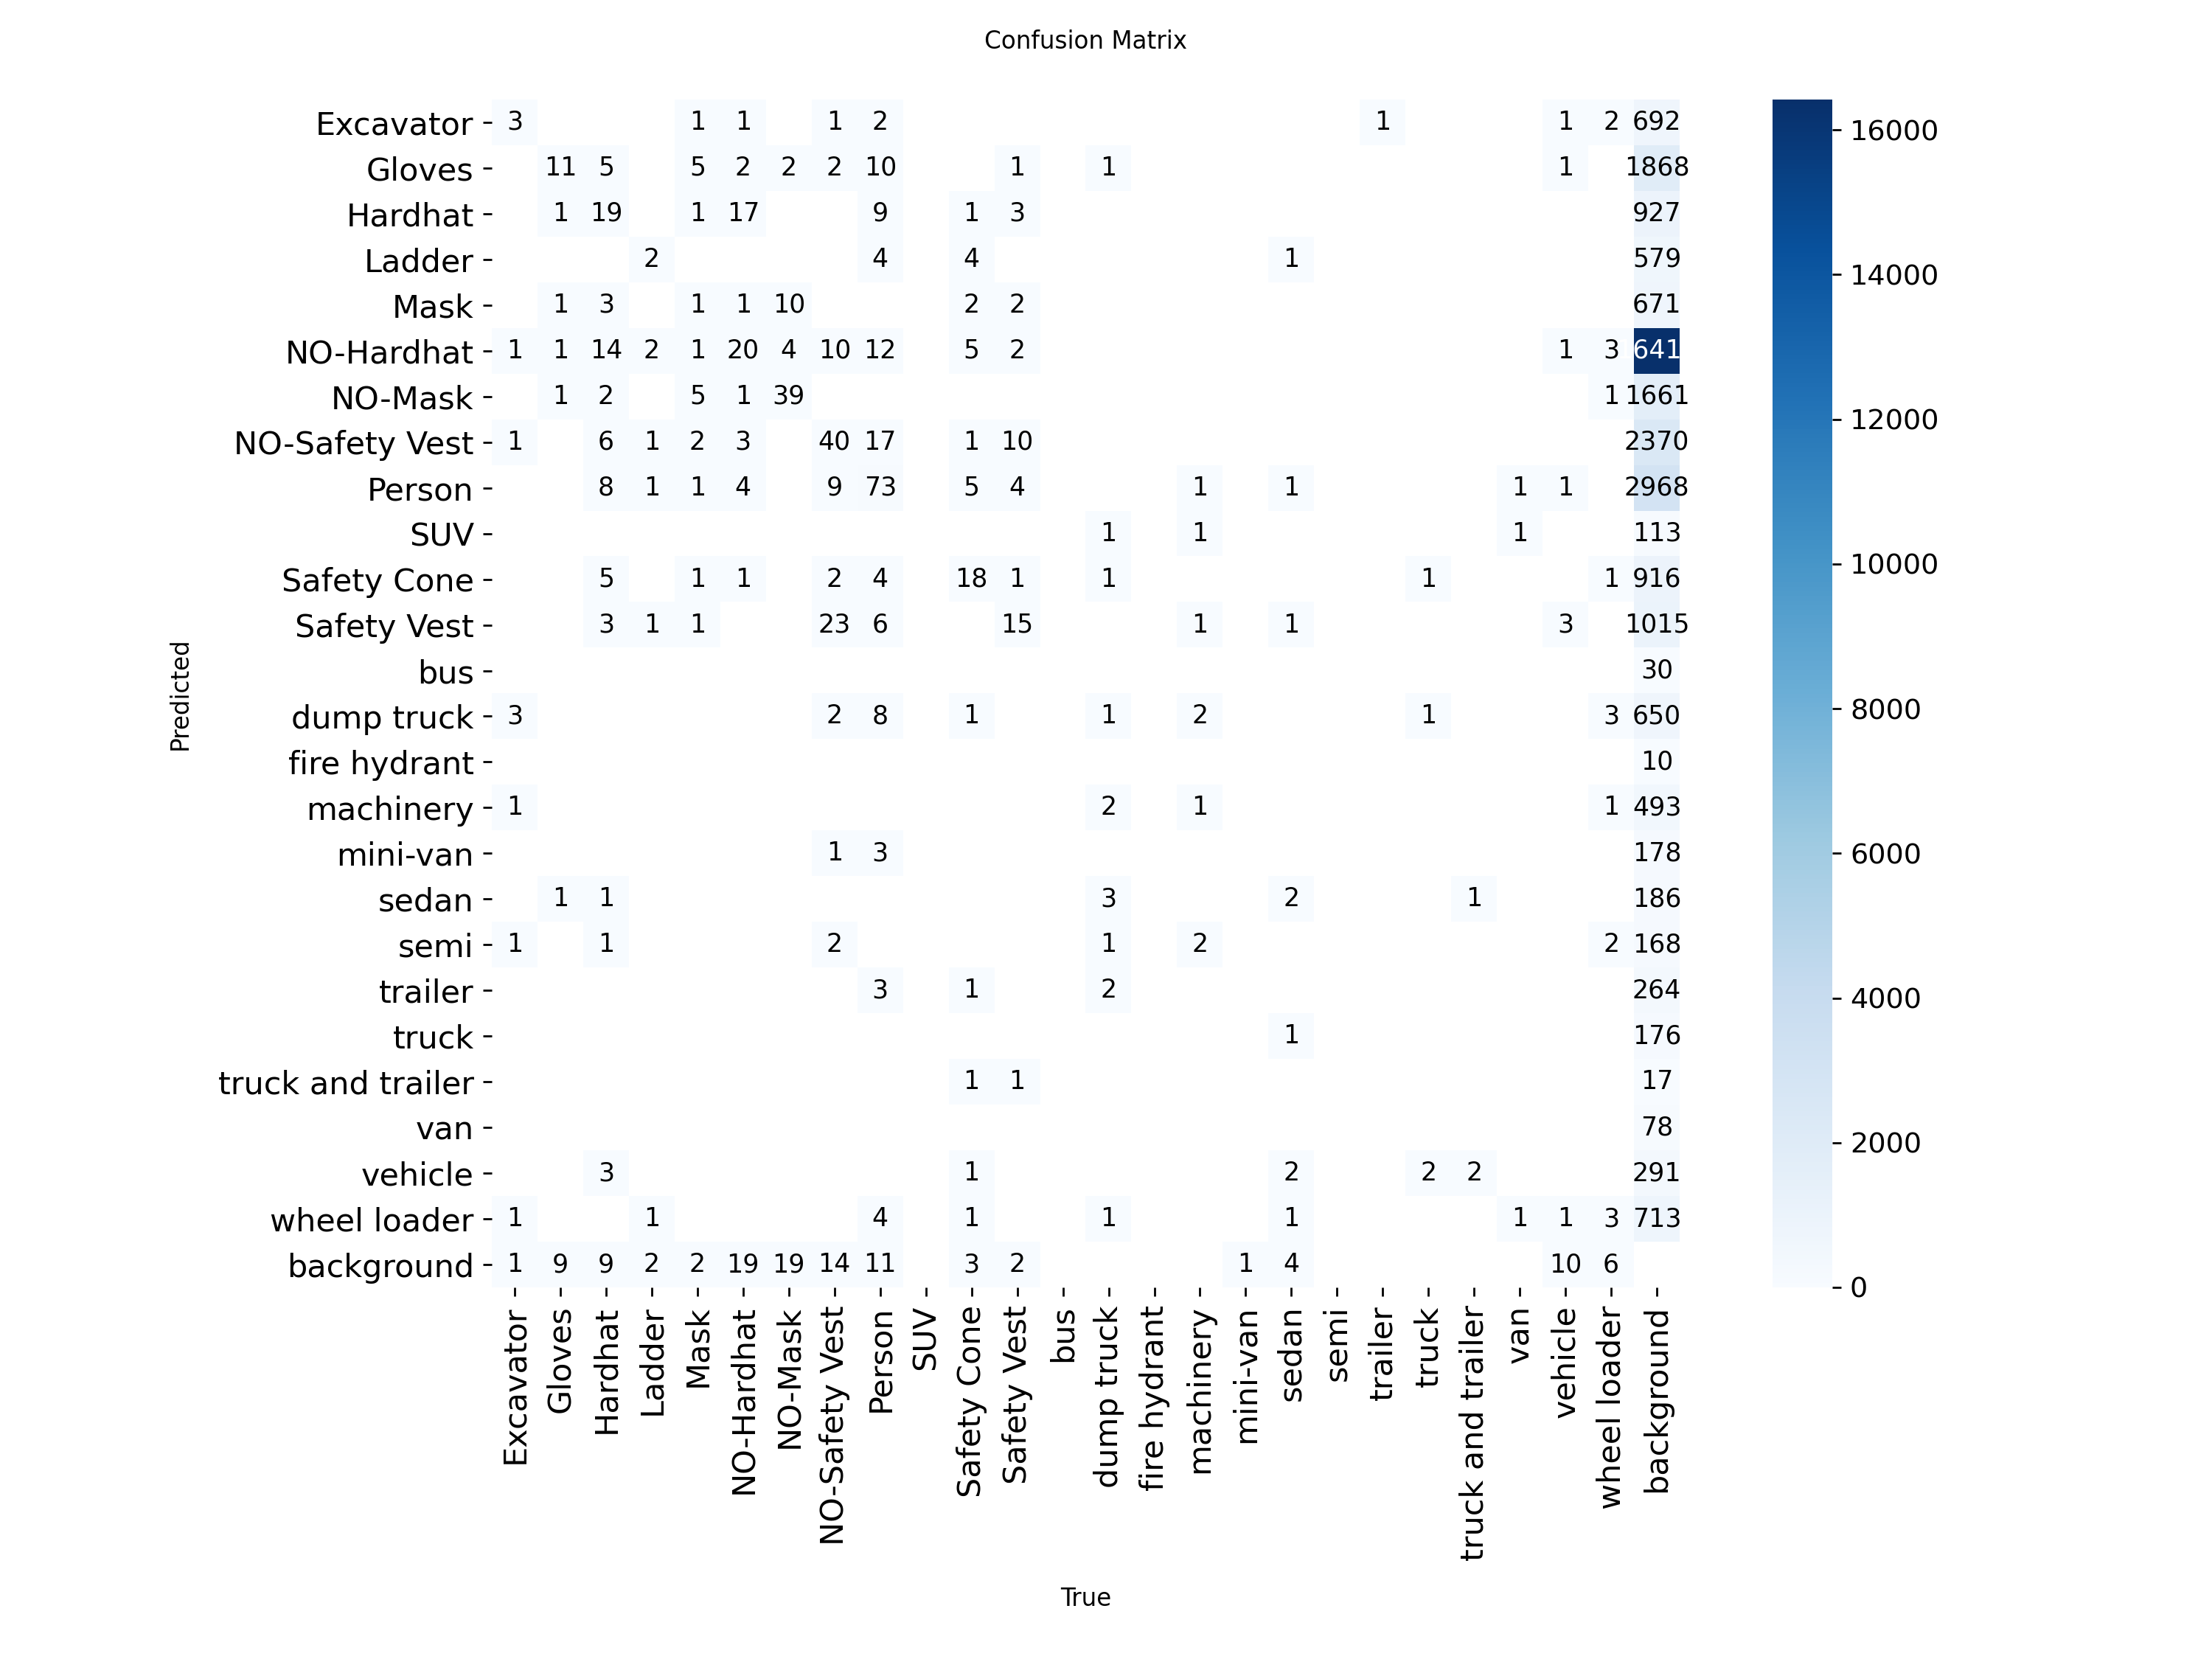

In [10]:
from pathlib import Path
from IPython.display import display, Image

run_dir = Path("/content/construction_risk_training/yolov8n_trial")

print("Training artifacts:")
for path in sorted(run_dir.glob("*.png")):
    print(path.name)

print("\nSaved validation prediction images:")
for path in sorted(run_dir.glob("val_batch*_pred.jpg")):
    print(path.name)

# Display training metrics
for filename in ["results.png", "confusion_matrix.png"]:
    path = run_dir / filename
    if path.exists():
        print(f"\n{filename}")
        display(Image(filename=str(path)))


val_batch0_pred.jpg


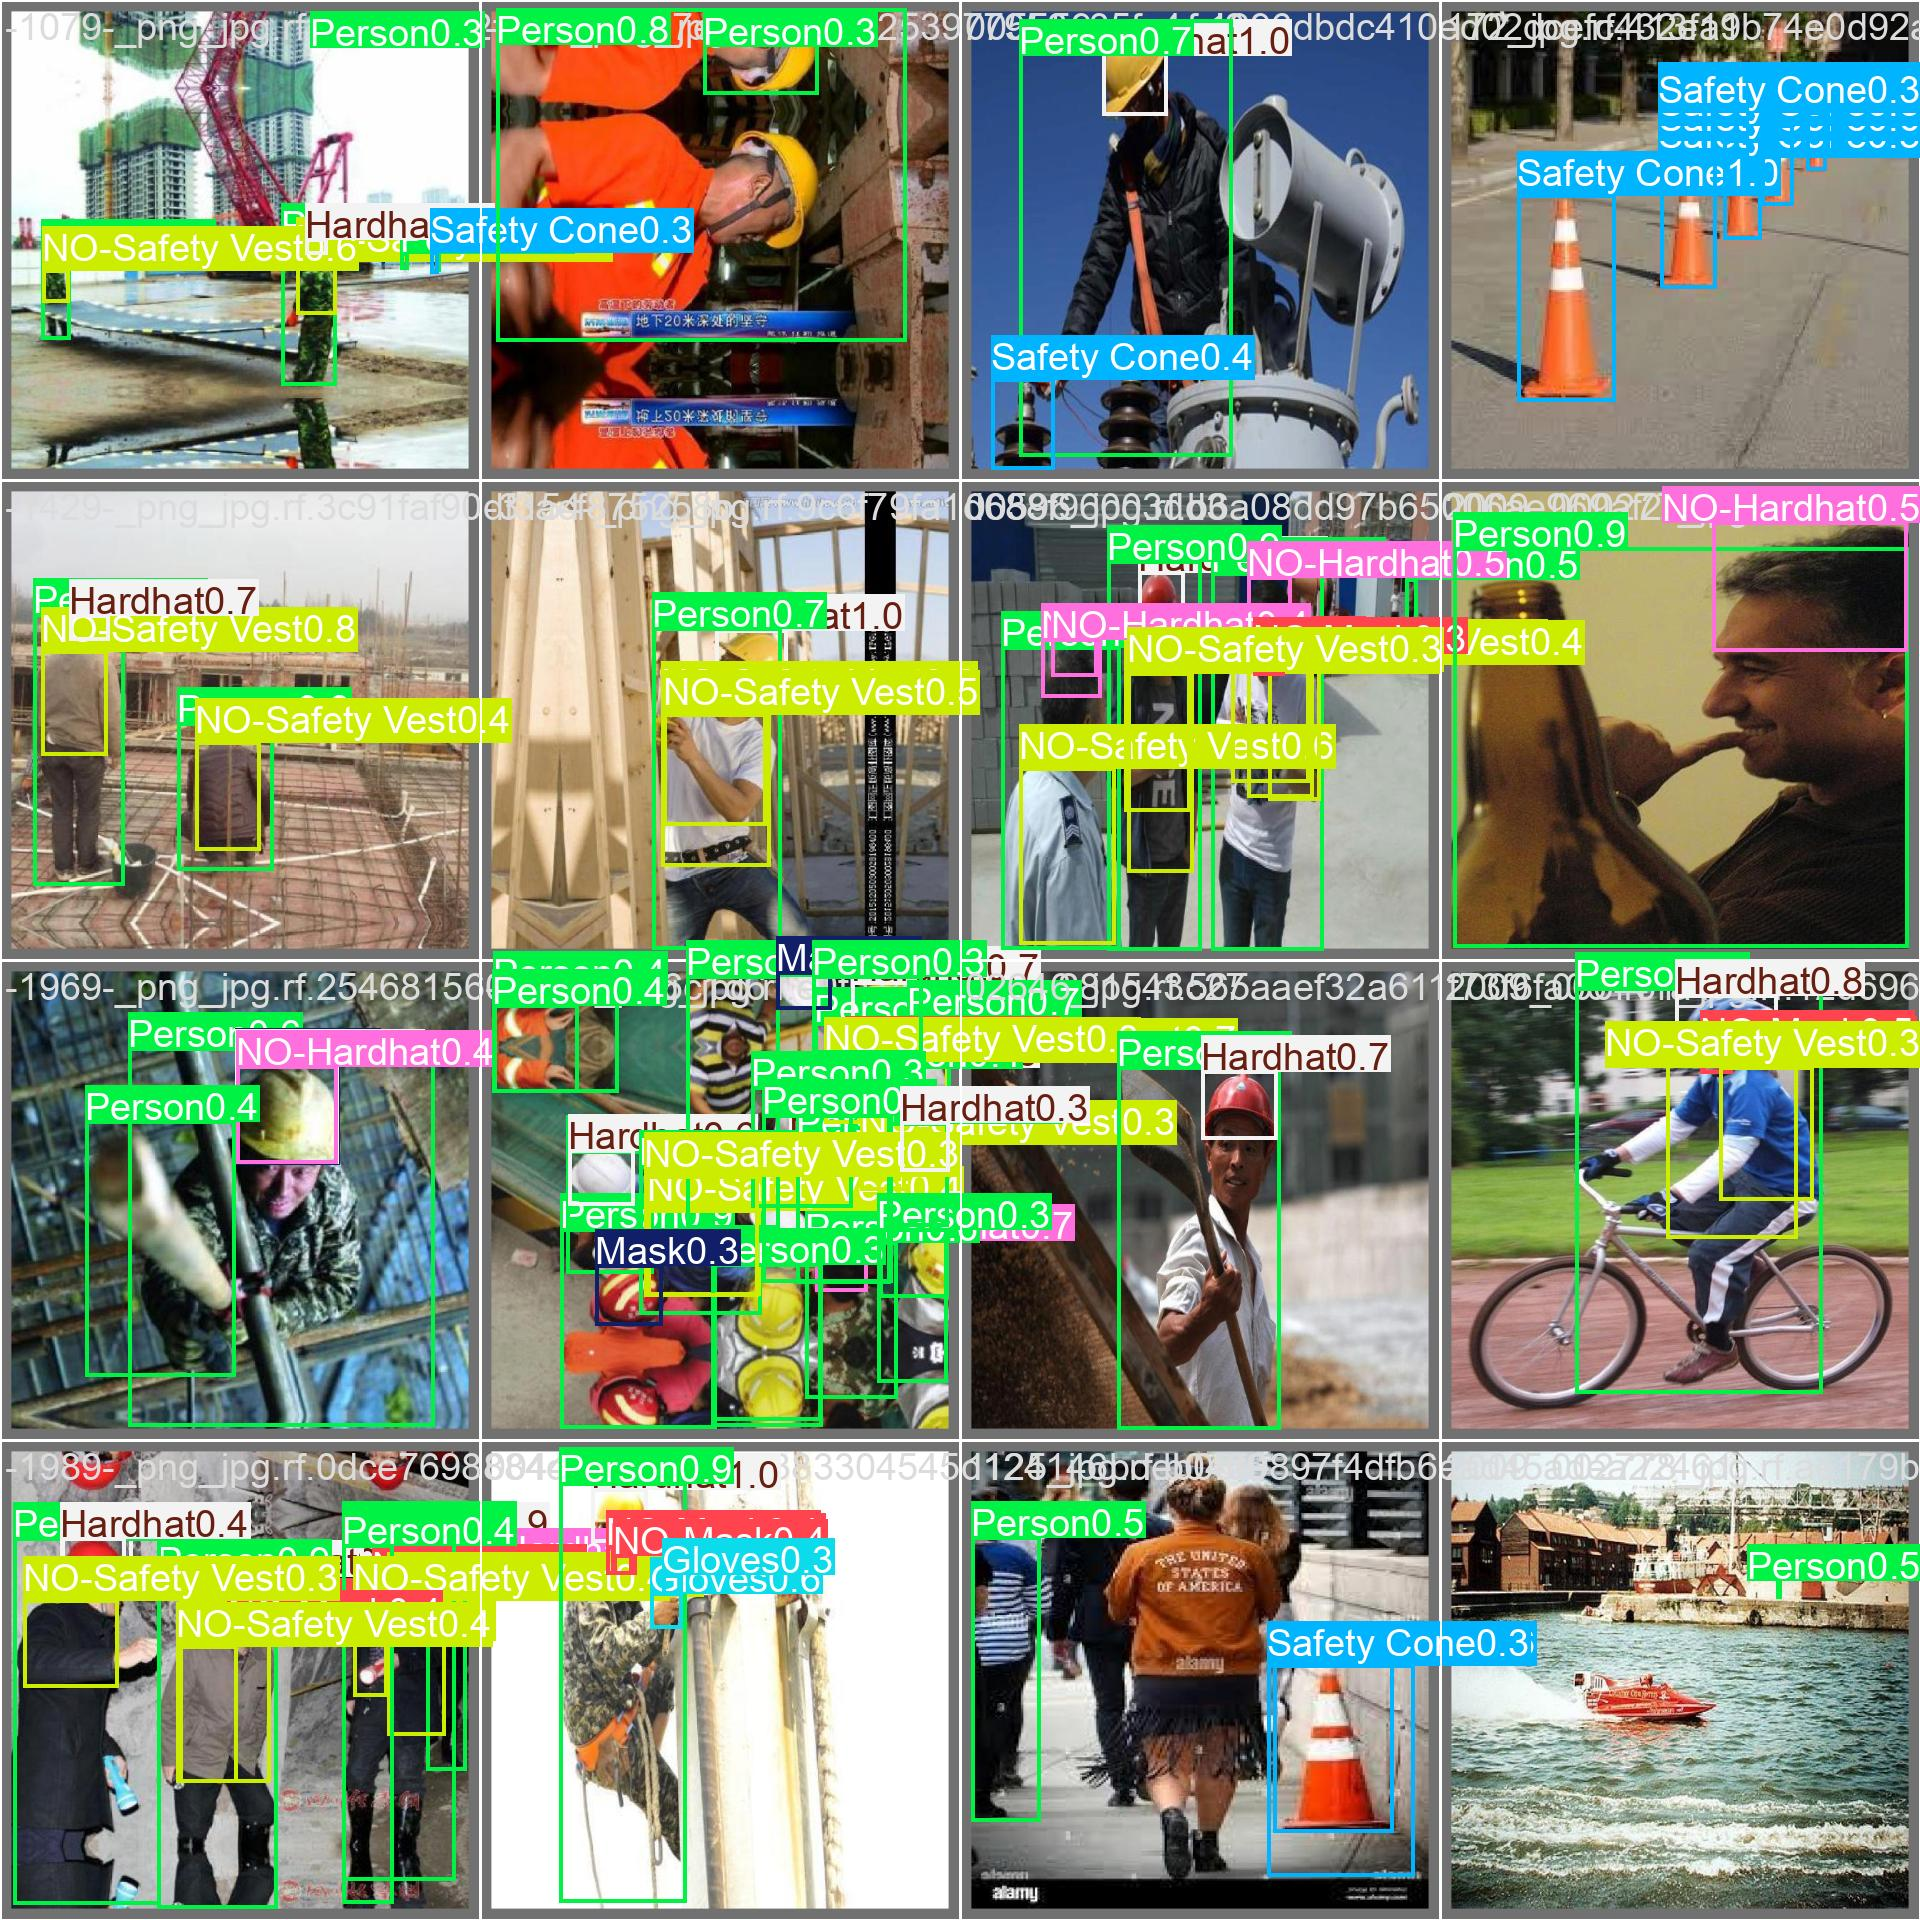

val_batch1_pred.jpg


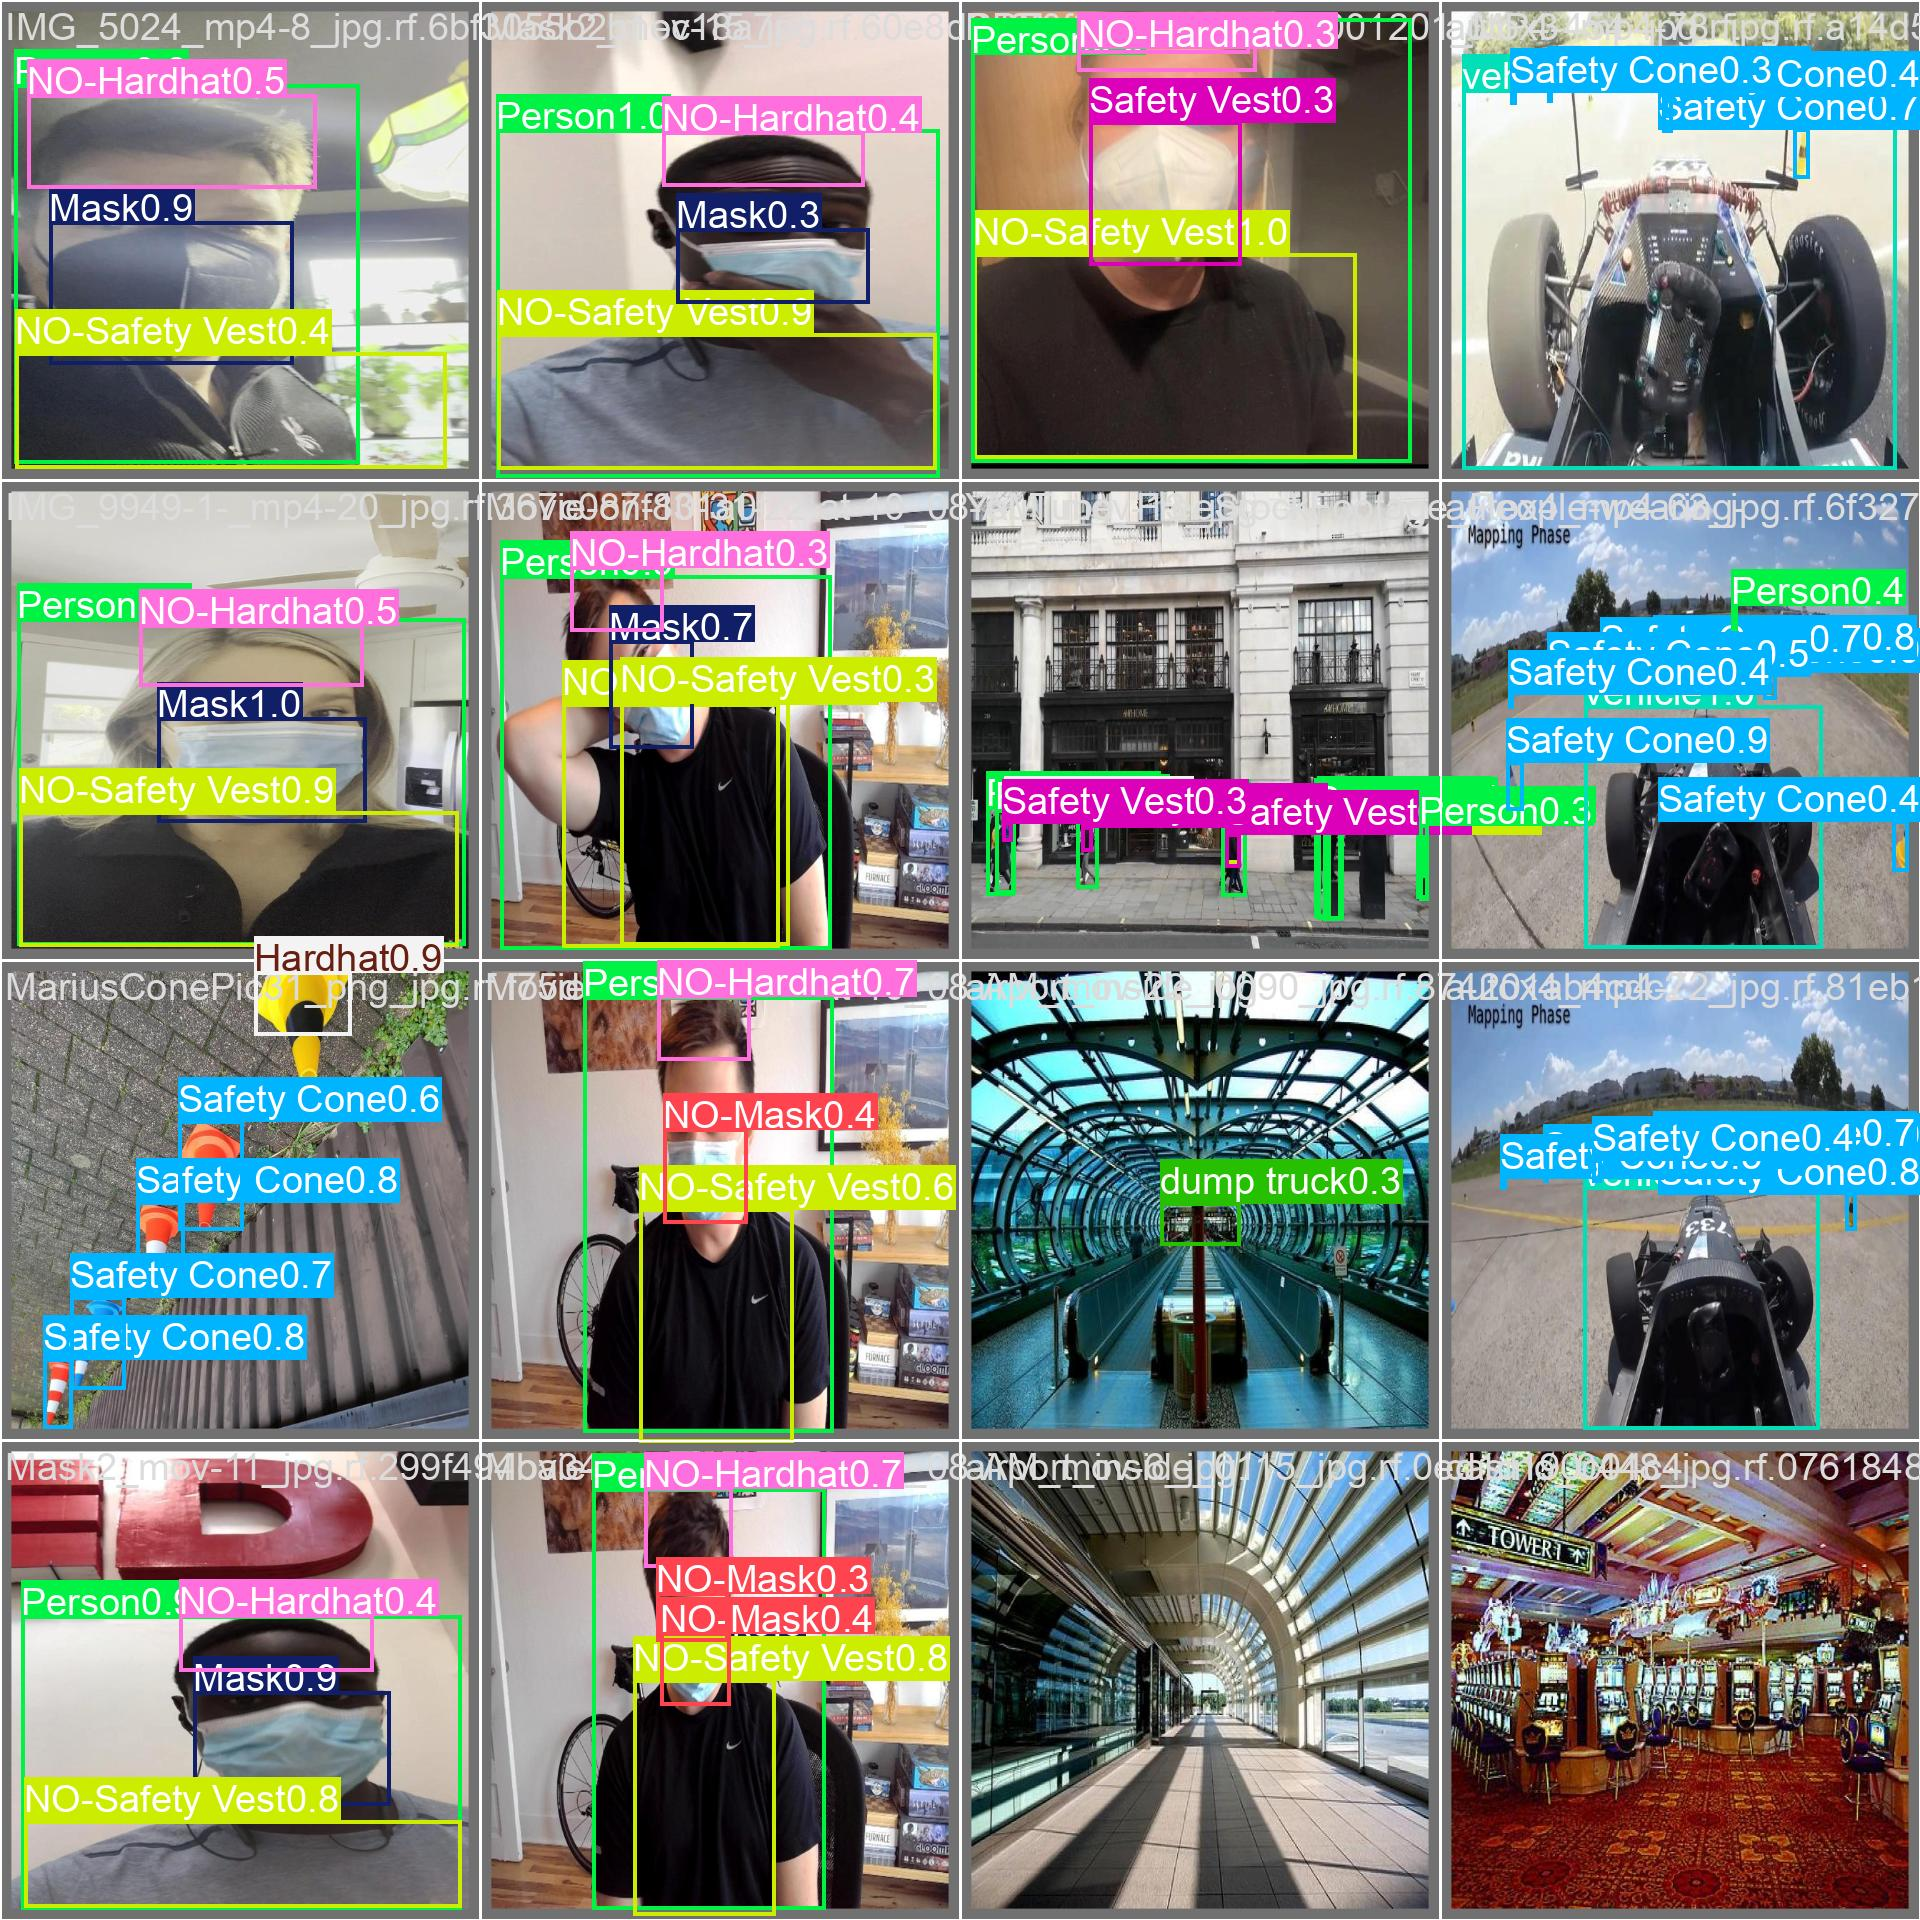

val_batch2_pred.jpg


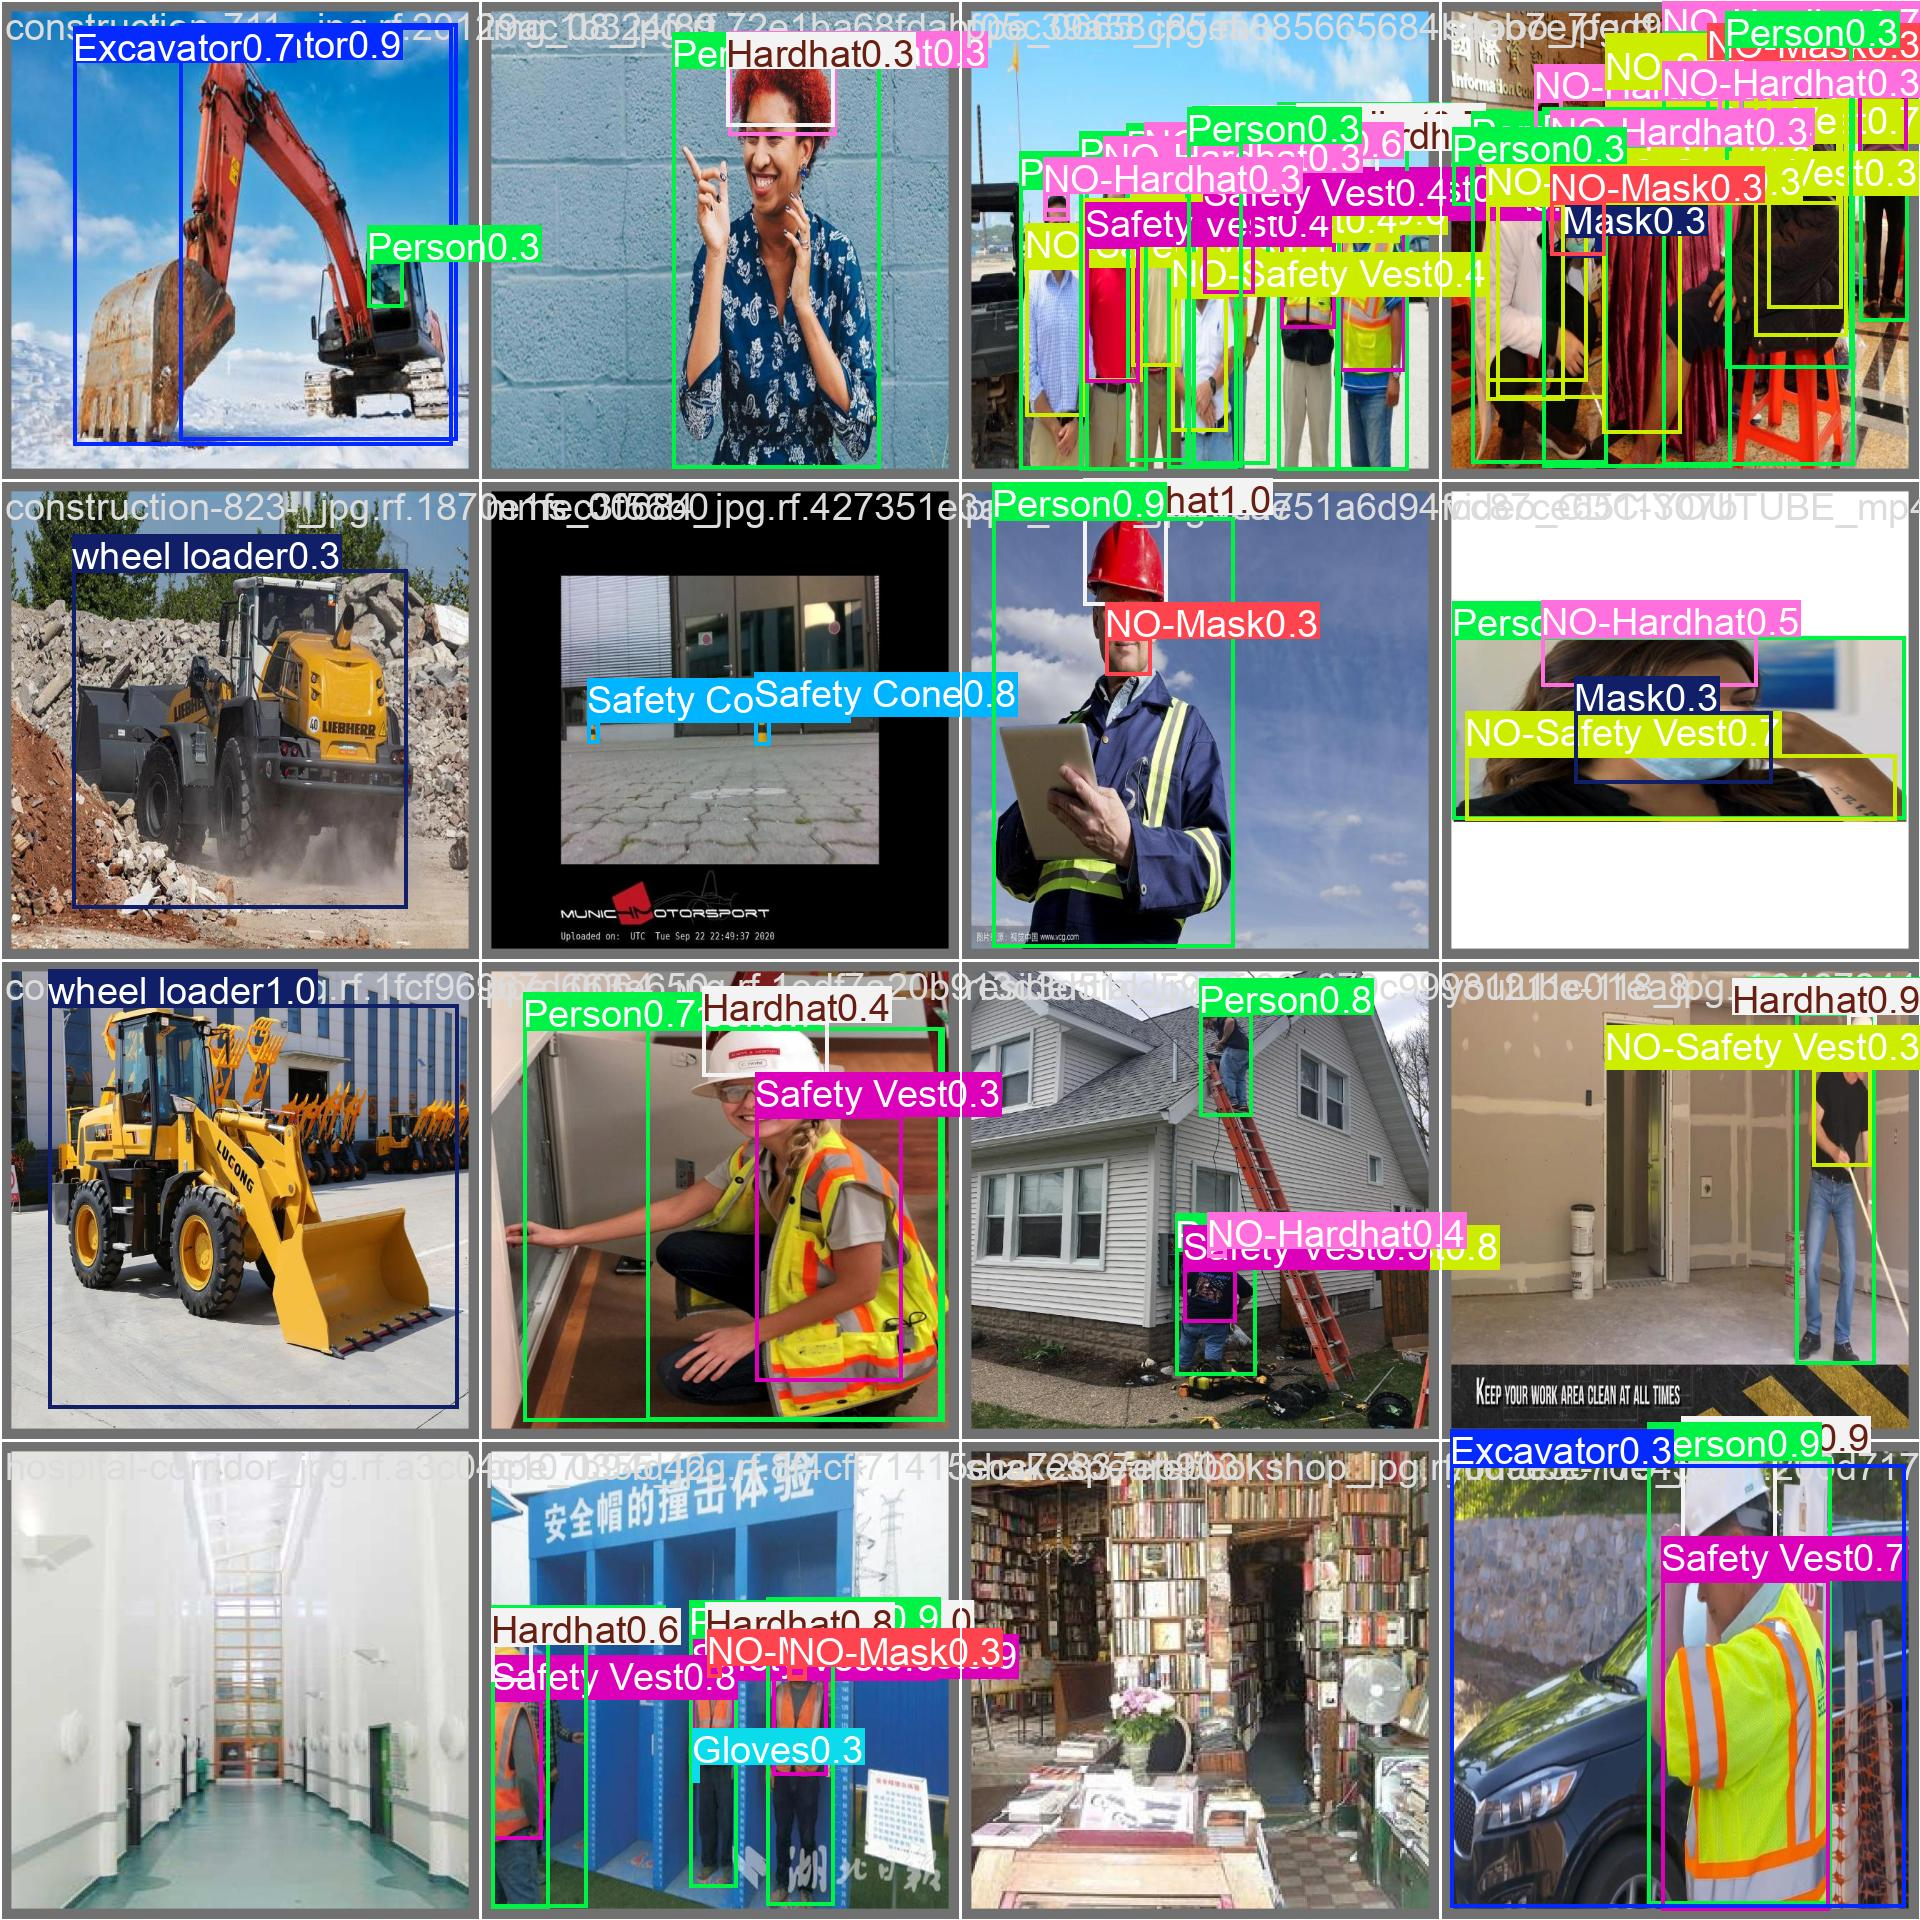

In [12]:
from pathlib import Path
from IPython.display import display, Image

run_dir = Path("/content/construction_risk_training/yolov8n_trial")
predictions = sorted(run_dir.glob("val_batch*_pred.jpg"))

if predictions:
    for path in predictions[:3]:
        print(path.name)
        display(Image(filename=str(path), width=800))
else:
    print("No saved validation prediction images found.")

In [13]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO(
    "/content/construction_risk_training/yolov8n_trial/weights/best.pt"
)

results = model.predict(
    source="/content/dataset/valid/images",
    conf=0.50,
    save=True,
    project="/content/construction_risk_training",
    name="validation_conf50",
    max_det=50
)

print("Images evaluated:", len(results))
print("Predictions saved to:")
print("/content/construction_risk_training/validation_conf50")


image 1/114 /content/dataset/valid/images/-1079-_png_jpg.rf.b5df117d2f459522987e48fdf0f80564.jpg: 640x640 1 Hardhat, 2 NO-Safety Vests, 4 Persons, 1 Safety Vest, 12.5ms
image 2/114 /content/dataset/valid/images/-1429-_png_jpg.rf.3c91faf90df3acf875258beb103a48ce.jpg: 640x640 1 Hardhat, 1 NO-Safety Vest, 2 Persons, 12.5ms
image 3/114 /content/dataset/valid/images/-1969-_png_jpg.rf.2546815605c97d73f6c1d69bc917ce84.jpg: 640x640 1 Hardhat, 13.4ms
image 4/114 /content/dataset/valid/images/-1989-_png_jpg.rf.0dce7698884d8b66f96db10ac14476c2.jpg: 640x640 3 Hardhats, 1 NO-Hardhat, 4 NO-Masks, 1 NO-Safety Vest, 4 Persons, 12.7ms
image 5/114 /content/dataset/valid/images/-211-_png_jpg.rf.8a895253977953a35fc4ed0d0270ae6c.jpg: 640x640 1 Person, 12.5ms
image 6/114 /content/dataset/valid/images/-3154-_png_jpg.rf.9c6f79fa1d688f96003dd3bf2c0a8f19.jpg: 640x640 1 Hardhat, 1 NO-Safety Vest, 1 Person, 12.5ms
image 7/114 /content/dataset/valid/images/-3766-_png_jpg.rf.e0fb145569c3b281543c27f37f2ba7da.jpg: 6

In [2]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.6 MB/s eta 0:00:00


In [3]:
from pathlib import Path

weights = Path(
    "/content/construction_risk_training/yolov8n_trial/weights/best.pt"
)

print("Model file exists:", weights.exists())

if weights.exists():
    print(f"Model size: {weights.stat().st_size / (1024 * 1024):.2f} MB")

Model file exists: False


In [4]:
import os

for path in [
    "/content/dataset/data.yaml",
    "/content/Construction Site Safety.v1i.yolov8.zip",
    "/content/construction_risk_training/yolov8n_trial/weights/best.pt",
]:
    print(f"{'EXISTS' if os.path.exists(path) else 'MISSING'}: {path}")


MISSING: /content/dataset/data.yaml
MISSING: /content/Construction Site Safety.v1i.yolov8.zip
MISSING: /content/construction_risk_training/yolov8n_trial/weights/best.pt


In [5]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os

PROJECT_DIR = "/content/drive/MyDrive/construction_risk_project"
DATASET_DIR = f"{PROJECT_DIR}/dataset"
RUNS_DIR = f"{PROJECT_DIR}/training_runs"

os.makedirs(DATASET_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

print("Project folder ready:", PROJECT_DIR)
print("Dataset folder ready:", DATASET_DIR)
print("Training output folder ready:", RUNS_DIR)

Project folder ready: /content/drive/MyDrive/construction_risk_project
Dataset folder ready: /content/drive/MyDrive/construction_risk_project/dataset
Training output folder ready: /content/drive/MyDrive/construction_risk_project/training_runs


In [7]:
from google.colab import files
import shutil
import os

uploaded = files.upload()

for filename in uploaded:
    if filename.lower().endswith(".zip"):
        destination = os.path.join(
            "/content/drive/MyDrive/construction_risk_project",
            filename
        )
        shutil.copy2(filename, destination)
        print("Saved permanently to:", destination)


Saving Construction Site Safety.v1i.yolov8.zip to Construction Site Safety.v1i.yolov8.zip
Saved permanently to: /content/drive/MyDrive/construction_risk_project/Construction Site Safety.v1i.yolov8.zip


In [8]:
import zipfile
import os

ZIP_PATH = (
    "/content/drive/MyDrive/construction_risk_project/"
    "Construction Site Safety.v1i.yolov8.zip"
)

DATASET_DIR = (
    "/content/drive/MyDrive/construction_risk_project/dataset"
)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATASET_DIR)

print("Extraction complete.")
print("Dataset contents:", os.listdir(DATASET_DIR))

Extraction complete.
Dataset contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


In [9]:
import yaml
from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/construction_risk_project/dataset"
)

yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

data["path"] = str(DATASET_DIR)
data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Updated:", yaml_path)
print("Classes:", data["nc"])
print("Training images:", len(list((DATASET_DIR / "train/images").glob("*.jpg"))))
print("Validation images:", len(list((DATASET_DIR / "valid/images").glob("*.jpg"))))
print("Test images:", len(list((DATASET_DIR / "test/images").glob("*.jpg"))))

Updated: /content/drive/MyDrive/construction_risk_project/dataset/data.yaml
Classes: 25
Training images: 521
Validation images: 114
Test images: 82


In [10]:
%pip install -q ultralytics

In [11]:
from ultralytics import YOLO
import torch
from pathlib import Path

assert torch.cuda.is_available(), "GPU not available. Enable the T4 GPU."

DATASET_YAML = (
    "/content/drive/MyDrive/construction_risk_project/"
    "dataset/data.yaml"
)

RUNS_DIR = (
    "/content/drive/MyDrive/construction_risk_project/"
    "training_runs"
)

model = YOLO("yolov8n.pt")

results = model.train(
    data=DATASET_YAML,
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project=RUNS_DIR,
    name="yolov8n_trial",
    exist_ok=True,
    seed=42,
    plots=True
)

best_weights = Path(RUNS_DIR) / "yolov8n_trial" / "weights" / "best.pt"

print("\nTraining finished.")
print("Best weights exist:", best_weights.exists())

if best_weights.exists():
    print(f"Checkpoint size: {best_weights.stat().st_size / (1024 * 1024):.2f} MB")
    print("Persistent checkpoint:", best_weights)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/construction_risk_project/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.

In [12]:
from pathlib import Path

best_weights = Path(
    "/content/drive/MyDrive/construction_risk_project/"
    "training_runs/yolov8n_trial/weights/best.pt"
)

print("Checkpoint exists:", best_weights.exists())
print("Checkpoint size (MB):", round(best_weights.stat().st_size / (1024 * 1024), 2))
print("Saved in Google Drive:", str(best_weights))

Checkpoint exists: True
Checkpoint size (MB): 6.21
Saved in Google Drive: /content/drive/MyDrive/construction_risk_project/training_runs/yolov8n_trial/weights/best.pt


In [13]:
from google.colab import files
from pathlib import Path

best_weights = Path(
    "/content/drive/MyDrive/construction_risk_project/"
    "training_runs/yolov8n_trial/weights/best.pt"
)

files.download(str(best_weights))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>